## Exploration Vs Exploitation
The exploration–exploitation dilemma is one of the fundamental challenges in deep reinforcement learning (RL). Agents must strike a trade-off between making decisions based on current beliefs or gathering more information.
If we have learned all the information about the environment, we are able to find the best strategy by even just simulating brute-force, let alone many other smart approaches. The dilemma comes from the incomplete information: we need to gather enough information to make best overall decisions while keeping the risk under control. With exploitation, we take advantage of the best option we know. With exploration, we take some risk to collect information about unknown options. The best long-term strategy may involve short-term sacrifices. For example, one exploration trial could be a total failure, but it warns us of not taking that action too often in the future. Thus, we want strategies that exploit what we think are the best actions so far, but still explore other actions. The exploration vs. exploitation tradeoff is often studied under more general
models such as MDPs.

## Multi-Armed Bandit
The multi-armed bandit (MAB) problem is a classic problem that well demonstrates the exploration vs exploitation dilemma. The MAB problem for a gambler is to decide which arm of a K-slot machine to pull to maximize his total reward in a series of trials. Many real-world learning and optimization problems can be modeled in this way.
In the k-armed bandit problem, each of the k actions has an expected or mean reward given that that action is selected; it's the value of that action. We denote the action selected on time step t as $A_t$, and the corresponding reward as $R_t$. The value then
of an arbitrary action a, denoted $q_*(a)$, is the expected reward given that a is selected:
\
    \begin{aligned}
    q_*(a) = \mathbb{E}[R_t | A_t = a]
    \end{aligned}
\
If we knew the value of each action, then it would be trivial to solve the k-armed bandit problem: we would always select the action with highest value. We assume that you do not know the action values with certainty, although you may have estimates. We denote the estimated value of action $a$ at time step $t$ as $Q_t(a)$. We would like $Q_t(a)$ to be close to $q_*(a)$.

## Bandit Strategies (Action-Value Methods)
**The ($\epsilon$)-Greedy Methods**    
 
The simplest action selection rule is to select one of the actions with the highest estimated value, that is, one of the greedy actions. If there is more than one greedy action, then a selection is made among them in some arbitrary way, perhaps randomly. We write this greedy action selection method as
\
\begin{aligned}
    A_t = argmaxQ_t(a)
    \end{aligned}
\
Greedy action selection always exploits current knowledge to maximize immediate reward; it spends no time at all sampling apparently inferior actions to see if they might really be better. A simple alternative is to behave greedily most of the time, but every once in a while, say with small probability $\epsilon$, instead select randomly from among all the actions with equal probability, independently of the action-value estimates. We call methods using this near-greedy action selection rule $\epsilon$-greedy methods.


We structure our code with a main ABC class (Base Bandit). Every algorithm represents a subclass that inherits from the main class. The environemnt structure represents the environment associated with each algorithm.

In [2]:
from MAB_Agents import *

In [3]:
from abc import ABC, abstractmethod

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta
from tqdm import trange

from environment import (
    BanditEnvironment,
    BernoulliBanditEnvironment,
    GaussianBanditEnvironment,
)

class Base_Bandit(ABC):
    # @k_arm: # of arms
    # @epsilon: probability for exploration in epsilon-greedy algorithm
    # @initial: initial estimation for each action
    # @step_size: constant step size for updating estimations
    # @sample_averages: if True, use sample averages to update estimations instead of constant step size

    def __init__(
        self,
        env: BanditEnvironment,
        epsilon=0.0,
        initial=0.0,
        step_size=0.1,
        sample_averages=False,
    ):
        self.env = env
        self.k = env.num_actions
        self.step_size = step_size
        self.sample_averages = sample_averages
        self.indices = np.arange(self.k)
        self.epsilon = epsilon
        self.initial = initial

        self.average_reward = 0
        self.time = 0
        # estimation for each action
        self.q_estimation = np.zeros(self.k) + self.initial
        # # of chosen times for each action
        self.action_count = np.zeros(self.k)

    def reset(self):
        # estimation for each action
        self.q_estimation = np.zeros(self.k) + self.initial
        # # of chosen times for each action
        self.action_count = np.zeros(self.k)
        self.time = 0
        self.average_reward = 0

    # get an action for this bandit
    @abstractmethod
    def act(self) -> int:
        pass

    # take an action, update estimation for this action
    def step(self, action):
        # generate the reward under N(real reward, 1)
        reward = self.env.get_reward(action)
        self.time += 1
        self.action_count[action] += 1
        self.average_reward += (reward - self.average_reward) / self.time

        if self.sample_averages:
            # update estimation using sample averages
            self.q_estimation[action] += (
                reward - self.q_estimation[action]
            ) / self.action_count[action]
        else:
            # update estimation with constant step size
            self.q_estimation[action] += self.step_size * (
                reward - self.q_estimation[action]
            )

        return reward

In [4]:
import random
from abc import ABC, abstractmethod

import numpy as np


class BanditEnvironment(ABC):
    """Abstract base class for bandit environments"""

    def __init__(self, num_actions: int):
        self._num_actions = num_actions
        self._best_action = None

    @abstractmethod
    def reset(self):
        pass

    @abstractmethod
    def get_reward(self, action) -> float:
        pass

    @property
    def best_action(self):
        return self._best_action

    @property
    def num_actions(self):
        return self._num_actions


class GaussianBanditEnvironment(BanditEnvironment):
    def __init__(self, num_actions: int = 10, true_reward: float = 0.0):
        super().__init__(num_actions)
        self.true_reward = true_reward
        self.q_true = np.random.randn(self.num_actions) + self.true_reward
        self._best_action = np.argmax(self.q_true)

    def reset(self):
        self.q_true = np.random.randn(self.num_actions) + self.true_reward
        self._best_action = np.argmax(self.q_true)

    def get_reward(self, action) -> float:
        return np.random.randn() + self.q_true[action]


class BernoulliBanditEnvironment(BanditEnvironment):
    def __init__(self, true_probs: list):
        super().__init__(len(true_probs))
        self.true_probs = np.array(true_probs)
        self._best_action = np.argmax(true_probs)

    def reset(self):
        pass

    def get_reward(self, action):
        return 1 if random.random() < self.true_probs[action] else 0

In [ ]:
class EpsilonGreedy(Base_Bandit):
    def act(self):
        if np.random.rand() < self.epsilon:
            return np.random.choice(self.indices)
        q_best = np.max(self.q_estimation)
        return np.random.choice(np.where(self.q_estimation == q_best)[0])

The upper figure compares a greedy method with two $\epsilon$-greedy methods ($\epsilon$=0.01 and $\epsilon$=0.1), on the 10-armed testbed. All the methods formed their action-value estimates using the sample-average technique. The upper graph shows the increase in expected reward with experience. The greedy method improved slightly faster than the other methods at the very beginning, but then leveled off at a lower level. It achieved a reward-per-step of only about 1, compared with the best possible of about 1.55 on this testbed. The greedy method performed significantly worse in the long run because it often got stuck performing suboptimal actions.   

The lower graph shows that the greedy method found the optimal action in only approximately one-third of the tasks. In the other two-thirds, its initial samples of the optimal action were disappointing, and it never returned to it. The $\epsilon$-greedy methods eventually performed better because they continued to explore and to improve their chances of recognizing the optimal action. The $\epsilon$ = 0.1 method explored more, and usually found the optimal action earlier, but it never selected that action more than 91% of the time. The $\epsilon$ = 0.01 method improved more slowly, but eventually would perform better than the $\epsilon$ = 0.1 method on both performance measures shown in the figure. It is also possible to reduce $\epsilon$ over time to try to get the best of both high and low values. 

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:26<00:00, 76.55it/s]


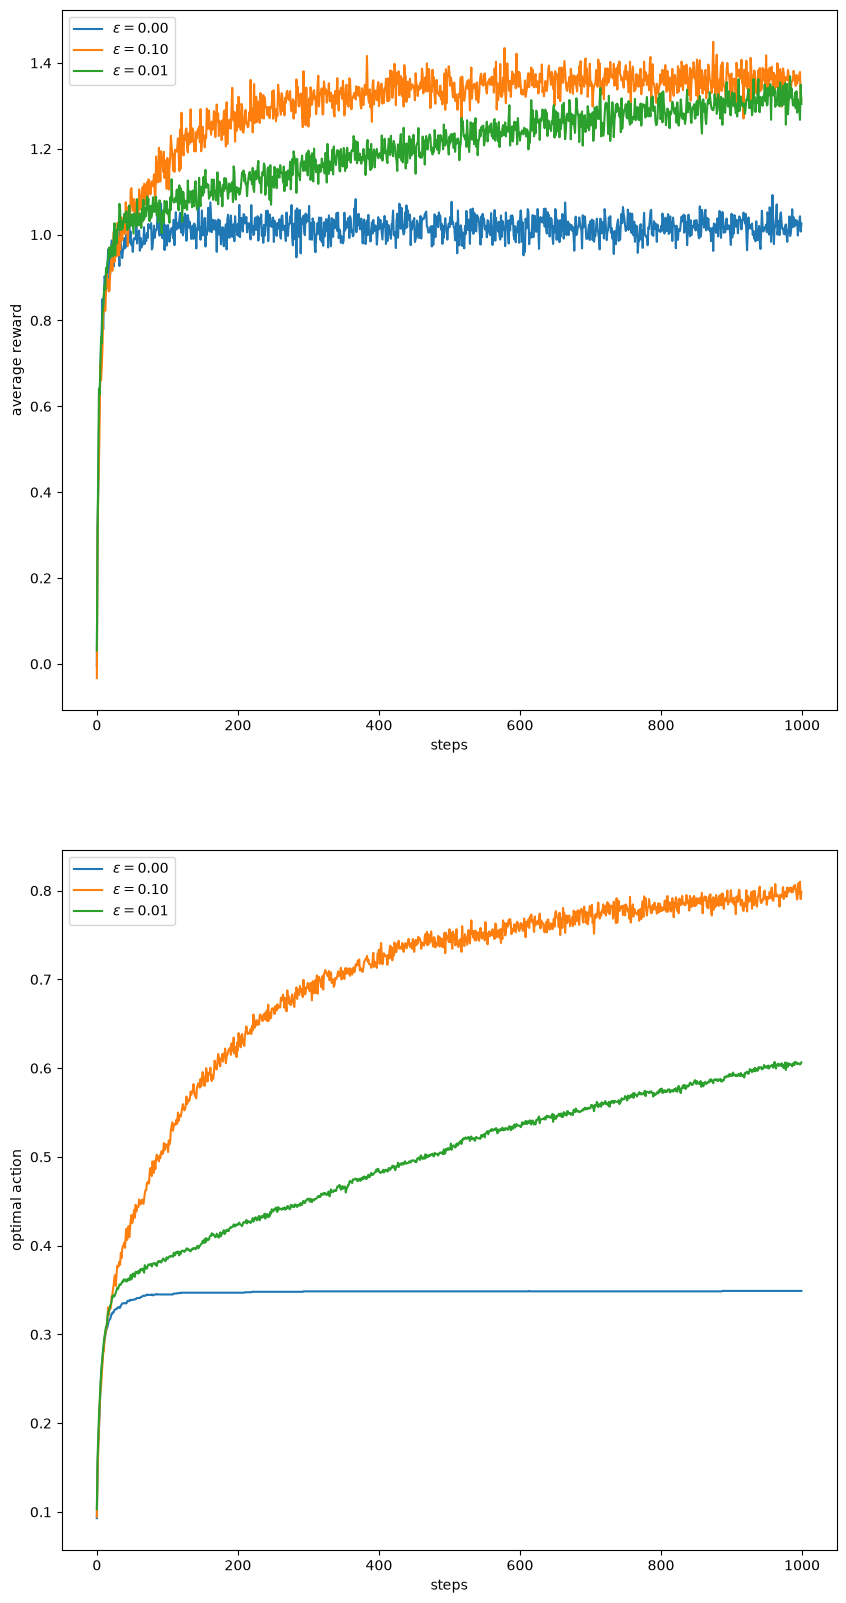

In [2]:
figure_epsilongreedy(show=True)

## Upper-Confidence-Bound Action Selection

Exploration is needed because there is always uncertainty about the accuracy of the action-value estimates. The greedy actions are those that look best at present, but some of the other actions may actually be better. $\epsilon$-greedy action selection forces the non-greedy
actions to be tried, but indiscriminately, with no preference for those that are nearly greedy or particularly uncertain. It would be better to select among the non-greedy actions according to their potential for actually being optimal, taking into account both how close their estimates are to being maximal and the uncertainties in those estimates. One effective way of doing this is to select actions according to:
$$
A_t \doteq \underset{a}{\arg\max} \left[ Q_t(a) + c \sqrt{\frac{\ln t}{N_t(a)}} \right],
$$
where ln t denotes the natural logarithm of t, $N_t(a)$ denotes the number of times that action a has been selected prior to time t, and the number c > 0 controls the degree of exploration. If Nt(a) = 0, then a is considered to be a maximizing action.
The idea of this upper confidence bound (UCB) action selection is that the square-root term is a measure of the uncertainty or variance in the estimate of a’s value. The quantity being max’ed over is thus a sort of upper bound on the possible true value of action a, with
c determining the confidence level. Each time a is selected the uncertainty is presumably reduced: $N_t(a)$ increments, and, as it appears in the denominator, the uncertainty term decreases. On the other hand, each time an action other than a is selected, t increases but Nt(a) does not; because t appears in the numerator, the uncertainty estimate increases. The use of the natural logarithm means that the increases get smaller over time, but are unbounded; all actions will eventually be selected, but actions with lower value estimates,
or that have already been selected frequently, will be selected with decreasing frequency over time.

In [ ]:
class UCB(Base_Bandit):
    def __init__(self, UCB_param=2, **kwargs):
        super().__init__(**kwargs)
        self.UCB_param = UCB_param

    def act(self) -> int:
        UCB_estimation = self.q_estimation + self.UCB_param * np.sqrt(
            np.log(self.time + 1) / (self.action_count + 1e-5)
        )
        q_best = np.max(UCB_estimation)
        return np.random.choice(np.where(UCB_estimation == q_best)[0])

Results with the UCB on the 10-armed testbed are shown in the figure below. The figure depicts average performance of UCB action selection on the 10-armed testbed. As shown, UCB often performs well, and it generally performs better than $\epsilon$-greedy action selection, except in the first k steps, when it selects randomly among the as-yet-untried actions.

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:24<00:00, 82.45it/s]


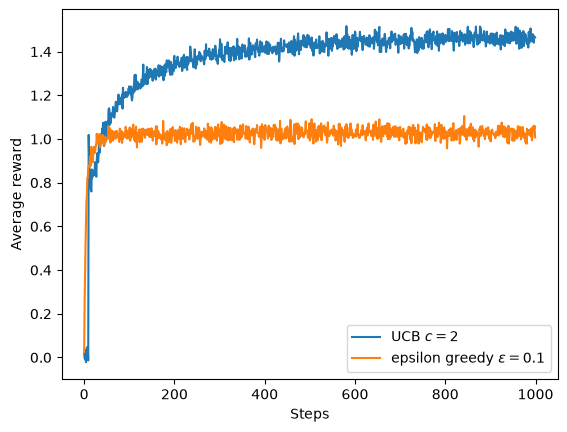

In [3]:
figure_UCB(show=True)

## Thompson Sampling 

Thompson Sampling (TS)—also known as posterior sampling or probability matching—resolves the exploration-exploitation dilemma naturally through Bayesian inference. Rather than acting on point estimates, the agent maintains a posterior probability distribution over the unknown parameters $\theta$. At each step, the agent samples a plausible parameter vector from its current beliefs and selects the action that is optimal under that sampled model. Consequently, each action is selected with a probability equal to the posterior probability that it is the optimal action

## General Mathematical Formulation

Consider a general sequential decision problem:
* Let $\mathcal{X}$ be the set of feasible actions.
* Let $\theta$ denote the unknown parameter governing the system's reward distribution, with prior probability distribution $p(\theta)$.
* At time $t = 1, 2, \dots$, the agent selects an action $x_t \in \mathcal{X}$, observes an outcome $y_t$ drawn from likelihood $q_\theta(\cdot \mid x_t)$, and receives reward $r_t = r(y_t)$.
* Let $\mathbb{H}_{t-1} = \big((x_1, y_1), \dots, (x_{t-1}, y_{t-1})\big)$ denote the history of observations up to time $t-1$.

### Step 1: Posterior Sampling
At iteration $t$, the agent draws a random parameter sample $\hat{\theta}$ from the current posterior distribution $p_t(\theta) = \mathbb{P}(\theta \in \cdot \mid \mathbb{H}_{t-1})$:

$$
\hat{\theta} \sim p_t(\theta)
$$

### Step 2: Action Selection (Probability Matching)
Assuming the sampled parameter $\hat{\theta}$ represents the true environment, the agent chooses the action $x_t$ that maximizes expected reward:

$$
x_t = \underset{x \in \mathcal{X}}{\arg\max} \; \mathbb{E}_{q_{\hat{\theta}}}\big[r(y_t) \mid x_t = x\big]
$$

For discrete outcomes, this expectation is written as:

$$
\mathbb{E}_{q_{\hat{\theta}}}\big[r(y_t) \mid x_t = x\big] = \sum_{o} q_{\hat{\theta}}(o \mid x)\, r(o)
$$

Because $\hat{\theta}$ is drawn from the posterior distribution, the probability of choosing action $x^*$ matches the posterior probability that $x^*$ is truly optimal:

$$
\mathbb{P}(x_t = x^* \mid \mathbb{H}_{t-1}) = \mathbb{P}\!\left(x^* = \underset{x \in \mathcal{X}}{\arg\max} \; \mathbb{E}_{q_{\theta}}[r(y_t) \mid x_t = x] \;\middle\vert{}\; \mathbb{H}_{t-1}\right)
$$

### Step 3: Bayesian Posterior Update
After applying $x_t$ and observing outcome $y_t$, the agent updates its belief distribution via **Bayes' rule**:

$$
p_{t+1}(\theta) = \mathbb{P}_{p_t, q}(\theta \mid x_t, y_t) = \frac{p_t(\theta)\, q_\theta(y_t \mid x_t)}{\int p_t(u)\, q_u(y_t \mid x_t)\, du}
$$

*(For discrete parameter spaces, the integral in the denominator is replaced by a sum $\sum_v p_t(v) q_v(y_t \mid x_t)$.)*

---

## Canonical Case: The Beta-Bernoulli Bandit

In the **Bernoulli Bandit**, there are $K$ arms. Pulling arm $k \in \{1, \dots, K\}$ yields a binary reward $r_t \in \{0, 1\}$ with unknown success probability $\theta_k \in [0, 1]$:

$$
\mathbb{P}(r_t = 1 \mid x_t = k, \theta) = \theta_k, \qquad \mathbb{P}(r_t = 0 \mid x_t = k, \theta) = 1 - \theta_k
$$

### Prior Distribution
Because the **Beta distribution** is the conjugate prior for the Bernoulli likelihood, we model the prior belief over each arm's success probability $\theta_k$ independently using $\text{Beta}(\alpha_k, \beta_k)$ with probability density function:

$$
p(\theta_k) = \frac{\Gamma(\alpha_k + \beta_k)}{\Gamma(\alpha_k)\Gamma(\beta_k)} \, \theta_k^{\alpha_k - 1} (1 - \theta_k)^{\beta_k - 1}
$$

where $\Gamma(\cdot)$ is the gamma function. Setting $\alpha_k = \beta_k = 1$ yields a uniform prior $\text{Uniform}(0, 1)$. The mean of this distribution is $\mathbb{E}[\theta_k] = \frac{\alpha_k}{\alpha_k + \beta_k}$, and its variance shrinks as the pseudo-counts $\alpha_k + \beta_k$ grow.

### Algorithm Execution at Time $t$
1. **Sample from Posterior:** For each arm $k = 1, \dots, K$, draw a random success probability estimate:
   $$\hat{\theta}_k \sim \text{Beta}(\alpha_k, \beta_k)$$
2. **Select Action:** Pull the arm with the highest sampled value:
   $$x_t = \underset{k \in \{1, \dots, K\}}{\arg\max} \; \hat{\theta}_k$$
3. **Observe and Update:** Observe reward $r_t \in \{0, 1\}$ and update only the chosen arm's parameters:
   $$(\alpha_k, \beta_k) \leftarrow \begin{cases} (\alpha_k + r_t,\; \beta_k + 1 - r_t) & \text{if } x_t = k \\ (\alpha_k,\; \beta_k) & \text{if } x_t \neq k \end{cases}$$

---

## Performance Evaluation: Regret

The theoretical and empirical effectiveness of Thompson Sampling is measured using **regret**, which quantifies the reward lost by not always playing the optimal arm:

* **Per-Period Regret:** At time $t$, the expected difference between the optimal arm's mean reward and the selected arm's mean reward:
  $$\text{regret}_t(\theta) = \max_{k} \theta_k - \theta_{x_t}$$
* **Cumulative Regret:** The total expected regret accumulated over $T$ time steps:
  $$\text{Regret}(T) = \mathbb{E}\left[ \sum_{t=1}^{T} \left( \max_{k} \theta_k - \theta_{x_t} \right) \right]$$

As $t$ grows large, Thompson Sampling concentrates posterior probability mass onto the true optimal arm, causing per-period regret to decay toward zero and achieving optimal asymptotic logarithmic cumulative regret $\mathcal{O}(\ln T)$.


In [5]:
class ThompsonSampling(Base_Bandit):
    def __init__(
        self, env: BanditEnvironment, default_alpha=1, default_beta=1, **kwargs
    ):
        if not isinstance(env, BernoulliBanditEnvironment):
            raise TypeError(
                "ThompsonSampling requires a BernoulliBanditEnvironment instance."
            )
        # Thompson Sampling specific parameters
        self.default_alpha = default_alpha
        self.default_beta = default_beta

        # Call the superclass constructor with all remaining parameters
        super().__init__(env=env, **kwargs)

        # Initialize Thompson Sampling specific attributes using k from superclass
        self.alphas = [self.default_alpha] * self.k
        self.betas = [self.default_beta] * self.k
        self.successes = [0] * self.k
        self.failures = [0] * self.k

    def reset(self):
        super().reset()
        self.alphas = [self.default_alpha] * self.k
        self.betas = [self.default_beta] * self.k
        self.successes = [0] * self.k
        self.failures = [0] * self.k

    def act(self) -> int:
        samples = [np.random.beta(a, b) for a, b in zip(self.alphas, self.betas)]
        return int(np.argmax(samples))

    def step(self, action: int):
        """
        Simulates the environment: generates a reward based on true probabilities,
        updates the internal counts, and returns the reward.
        """
        reward = self.env.get_reward(action)
        self.time += 1
        self.action_count[action] += 1
        self.average_reward += (reward - self.average_reward) / self.time

        # update internal statistics
        if reward == 1:
            self.successes[action] += 1
            self.alphas[action] += 1
        else:
            self.failures[action] += 1
            self.betas[action] += 1

        return reward

    def plot_posteriors(self, arm_labels=None):
        # plots the Probability Density Function (PDF) of the Beta distribution for each arm."""
        n_arms = len(self.alphas)
        if arm_labels is None:
            arm_labels = [f"Arm {i + 1}" for i in range(n_arms)]

        x = np.linspace(0, 1, 1000)
        plt.figure(figsize=(10, 6))

        for i in range(n_arms):
            # calculate shape parameters: prior + observed
            a = self.alphas[i]  # equivalent to successes + prior_alpha
            b = self.betas[i]  # equivalent to failures + prior_beta

            pdf = beta.pdf(x, a, b)

            label = f"{arm_labels[i]} ($\\alpha$={a}, $\\beta$={b})"
            if i == self.env.best_action:
                plt.plot(x, pdf, label=label, linewidth=2.5, linestyle="--")
            else:
                plt.plot(x, pdf, label=label)

        plt.xlabel("Probability of Success ($\\theta$)")
        plt.ylabel("Probability Density")
        plt.title("Posterior Beta Distributions for Each Arm")
        plt.legend()
        plt.show()

The two figures illustrate how Thompson Sampling outperforms UCB (c = 2) on a 3-arm Bernoulli bandit problem with true success probabilities [0.2, 0.7, 0.5] and how the agent's posterior beliefs evolve over time. Together, the plots show probability matching in action. Because the High arm's posterior distribution sits almost entirely to the right of the other two curves, random samples $\hat{\theta}_k \sim \text{Beta}(\alpha_k, \beta_k)$ almost always favor the High arm while keeping just enough spread on uncertain arms to avoid getting stuck prematurely.

  0%|          | 0/2000 [00:00<?, ?it/s]

100%|██████████| 2000/2000 [00:43<00:00, 46.07it/s]


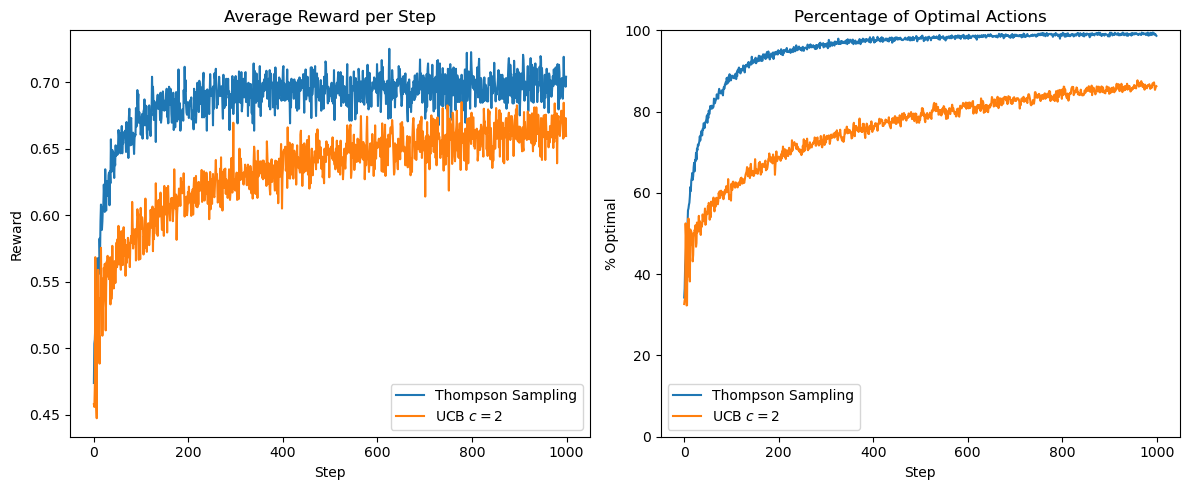

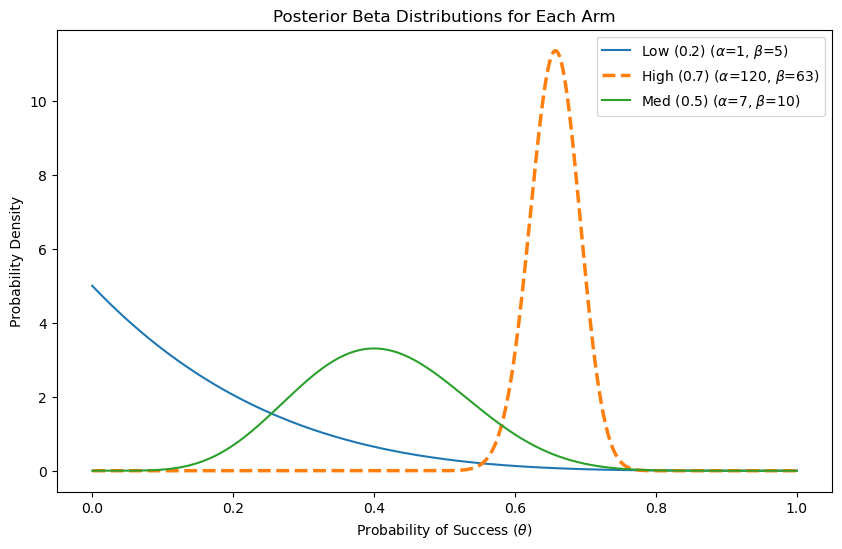

In [6]:
figure_TS(show=True)

## The Gittins Index Theorem

# <span style="font-size: 0.8em;"> Understanding Gittins Indices: From Complex Math to Clear Intuition </span>

## <span style="font-size: 0.8em;"> 1. Why Do Gittins Indices Feel So Hard? </span>
In a **Bayesian multi-armed bandit** problem, an agent wants to maximize total discounted rewards over time by choosing among $k$ uncertain options ("arms"). In theory, finding the exact optimal strategy requires solving a massive **Markov Decision Process (MDP)** using dynamic programming, which tracks every possible combination of outcomes across all arms simultaneously.

The **Gittins Index Theorem** solves this curse of dimensionality with a remarkable trick: **it decouples the arms**. Instead of comparing all $k$ arms against each other at once, you can evaluate **each arm completely on its own**, assign it a single number (its **Gittins index**), and simply pull the arm with the highest number at every step.

---

## <span style="font-size: 0.8em;"> 2. The "Fair Tax" Intuition (How to Think About the Index) </span>
To calculate the Gittins index of a single arm, imagine a simplified solo game (a **one-armed bandit**):

1. **The Setup:** You have one slot machine (arm) with an unknown true average payout $\theta$. Every time you pull it, you get a noisy reward $R_t$, and future rewards are discounted by a patience factor $\gamma \in (0, 1)$ (where $\gamma$ close to $1$ means you are a very patient agent who cares deeply about the future).
2. **The Tax ($\lambda$):** Suppose the casino charges you a flat fee—or **tax $\lambda$**—every single time you pull this arm.
3. **The Retirement Option:** At any point after the first pull, if you feel the arm isn't worth the tax, you can **retire** and walk away with $0$ reward forever.

### What is the Gittins Index?
The Gittins index $\lambda_\gamma$ is simply the **maximum "fair" tax** you would be willing to pay to play this game without losing money in expectation.
* If an arm has a **high expected reward**, you are willing to pay a high tax to play it.
* If an arm is **highly uncertain**, you are *also* willing to pay a surprisingly high tax! Why? Because you can test it a few times: if it turns out to be a jackpot, you keep playing forever; if it turns out to be a dud, you can just retire and stop paying the tax.

Thus, the Gittins index automatically bundles **exploitation** (current average reward) and **exploration** (the option value of discovering a hidden gem) into one single fair-price number.

---

## <span style="font-size: 0.8em;"> 3. The Mathematical Formulation (Step-by-Step) </span>

In a **Gaussian multi-armed bandit**, an arm's true mean $\theta$ is unknown, and pulling it at time $t$ produces a noisy reward $R_t \mid \theta \sim \mathcal{N}(\theta, \sigma_W^2)$, where $\sigma_W^2$ is the observation noise variance.

### <span style="font-size: 0.8em;"> Step 1: Updating Beliefs (Posterior State) </span>
After observing rewards $R_0, \dots, R_{t-1}$, your belief about the arm's true mean follows a normal distribution $\theta \mid R_0, \dots, R_{t-1} \sim \mathcal{N}(\mu_t, \sigma_t^2)$. Your current state is completely summarized by two numbers—your current estimate $\mu_t$ and your remaining uncertainty $\sigma_t^2$—which update after each pull via:

$$
\mu_t = \frac{\sigma_{t-1}^{-2}\mu_{t-1} + \sigma_W^{-2}R_{t-1}}{\sigma_{t-1}^{-2} + \sigma_W^{-2}} \qquad \text{and} \qquad \sigma_t^2 = \left(\frac{1}{\sigma_{t-1}^2} + \frac{1}{\sigma_W^2}\right)^{-1} = \left(\frac{1}{\sigma_0^2} + \frac{t}{\sigma_W^2}\right)^{-1}
$$

*(Notice how $\sigma_t^2$ shrinks toward zero as the number of pulls $t$ increases.)*

### <span style="font-size: 0.8em;"> Step 2: The Optimal Stopping Value Function </span>
Under a tax $\lambda$, the net expected reward of pulling the arm at state $(\mu_t, \sigma_t^2)$ is $\mu_t - \lambda$. Your goal is to choose the best **stopping time** $\tau \geq 1$ (the exact moment you decide to retire) to maximize your total discounted profit:

$$
V_\gamma^\lambda(\mu, \sigma) = \sup_{\tau \geq 1} \mathbb{E}\left[ \sum_{t=0}^{\tau} \gamma^t (\mu_t - \lambda) \;\middle\vert{}\; \mu_0 = \mu, \sigma_0^2 = \sigma^2 \right]
$$

### <span style="font-size: 0.8em;"> Step 3: Defining the Gittins Index </span>
The Gittins index $\lambda_\gamma(\mu, \sigma^2)$ is the highest tax $\lambda$ for which playing the game still yields a non-negative expected value:

$$
\lambda_\gamma(\mu, \sigma^2) = \sup \left\{ \lambda \in \mathbb{R} \;\middle\vert{}\; V_\gamma^\lambda(\mu, \sigma) \geq 0 \right\}
$$

---

## <span style="font-size: 0.8em;"> 4. The Big Revelation: Gittins Index &approx; Upper Confidence Bound </span>
Historically, computing $V_\gamma^\lambda(\mu, \sigma)$ required complex dynamic programming or numerical approximations. However, Russo's **Theorem 1** reveals that for a **patient agent** (whose discount factor $\gamma \to 1$), the Gittins index simplifies into an intuitive closed-form expression:

$$
\lambda_\gamma(\mu, \sigma^2) = \mu + \Phi^{-1}(\gamma)\sigma + o(1) \quad \text{as } \gamma \to 1
$$

where $\Phi^{-1}(\gamma)$ is the inverse cumulative distribution function (the $\gamma$-quantile) of the standard normal distribution $\mathcal{N}(0, 1)$, and $o(1)$ is an error term that vanishes as $\gamma \to 1$.

### Why This Makes Everything Click
Look at the two pieces of that equation:
1. **$\mu$ (Exploitation):** What you currently believe the arm pays on average.
2. **$\Phi^{-1}(\gamma)\sigma$ (Exploration Bonus):** A safety margin proportional to your uncertainty $\sigma$.

In plain English, **the Gittins index of a patient agent is simply the $\gamma$-quantile (the highest plausible value) of the arm's posterior distribution**. It behaves almost identically to a **Bayesian Upper Confidence Bound (UCB)** algorithm.

---

## <span style="font-size: 0.8em;"> 5. Applying It in Practice (And One Important Caveat) </span>

When running a multi-armed bandit with $k$ arms at time step $t$:
1. Maintain the posterior mean $\mu_{t,i}$ and posterior standard deviation $\sigma_{t,i}$ for each arm $i \in \{1, \dots, k\}$.
2. Compute each arm's index $\lambda_\gamma(\mu_{t,i}, \sigma_{t,i}^2)$ (or its patient approximation $\mu_{t,i} + \sigma_{t,i}\Phi^{-1}(\gamma)$).
3. **Select the arm with the largest index:**

$$
a_t = \underset{i \leq k}{\arg\max} \; \lambda_\gamma(\mu_{t,i}, \sigma_{t,i}^2)
$$

### When Does Exact Gittins Beat Standard UCB?
While Gittins indices and Bayesian UCB converge when the agent is very patient ($\gamma \to 1$, corresponding to an effective time horizon $T = \frac{1}{1-\gamma}$), they differ when time is short or rewards are very noisy:
* **Exact Gittins Indices** carefully account for both the remaining time horizon and the observation noise $\sigma_W^2$—refusing to waste pulls on an arm if the noise is too high to learn anything useful before time runs out.
* **Standard UCB** ignores noise-to-horizon ratios and can engage in wasteful exploration when observation noise is large relative to the problem's time horizon.


In [ ]:
class GittinsIndex(Base_Bandit):
    def __init__(self, discount_factor=0.99, **kwargs
    ):
        self.discount_factor = discount_factor
        super().__init__(**kwargs)

        # Initialize flat Beta(1,1) priors for each arm
        self.successes = np.zeros(self.k)
        self.failures = np.zeros(self.k)

    def act(self) -> int:
        """Finds and returns the index of the best arm to pull."""
        indices = []
        for i in range(self.k):
            idx = gittins_index_approx(
                self.successes[i], 
                self.failures[i], 
                self.discount_factor
            )
            indices.append(idx)
        return int(np.argmax(indices))

    def step(self, action):
        reward = self.env.get_reward(action)
        self.time += 1
        self.action_count[action] += 1
        self.average_reward += (reward - self.average_reward) / self.time

        if reward == 1:
            self.successes[action] += 1
        else:
            self.failures[action] += 1

        return reward      
    
    def reset(self):
        super().reset()
        self.successes = np.zeros(self.k)
        self.failures = np.zeros(self.k) 

In [ ]:
def gittins_index_approx(successes: int, failures: int, discount_factor: float = 0.9) -> float:
    """
    Approximates the Gittins index for a Beta-Bernoulli arm using the
    asymptotic equivalence to the posterior γ-quantile (Russo, 2014).

    GI ≈ μ + Φ⁻¹(γ) · σ   (as γ → 1)
    """
    alpha = successes + 1
    beta_param = failures + 1

    mean = alpha / (alpha + beta_param)
    variance = (alpha * beta_param) / ((alpha + beta_param)**2 * (alpha + beta_param + 1))
    std_dev = np.sqrt(variance)

    if discount_factor >= 1.0:
        return float(mean)  # undiscounted → pure exploitation

    scaling = norm.ppf(discount_factor)  # Φ⁻¹(γ)
    index_value = mean + scaling * std_dev

    return float(np.clip(index_value, 0.0, 1.0))

These two plots illustrate how the Gittins index balances exploration and exploitation internally and how it compares against Thompson Sampling and UCB in practice. The first figure shows why Gittins indices work—they add a principled, shrinking uncertainty bonus directly onto the posterior mean. The second figure shows the payoff—both Gittins Index and Thompson Sampling achieve near-optimal rewards much faster than standard UCB, with Gittins Index exhibiting slightly lower variance and faster early lock-in because it computes deterministic index scores rather than drawing random samples.

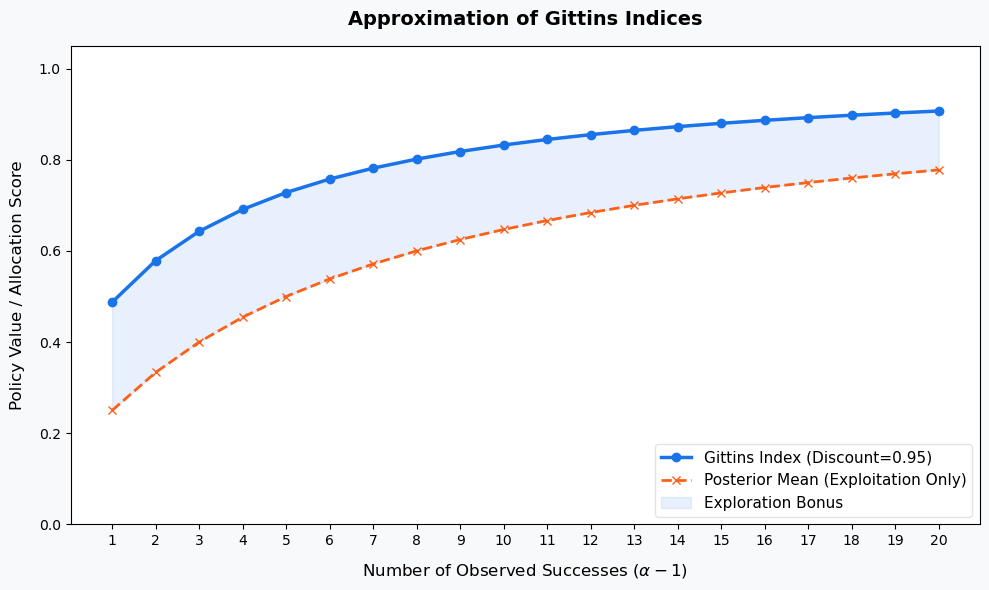

In [3]:
figure_Gittins(show=True)

  0%|          | 0/2000 [00:00<?, ?it/s]

100%|██████████| 2000/2000 [00:18<00:00, 108.46it/s]


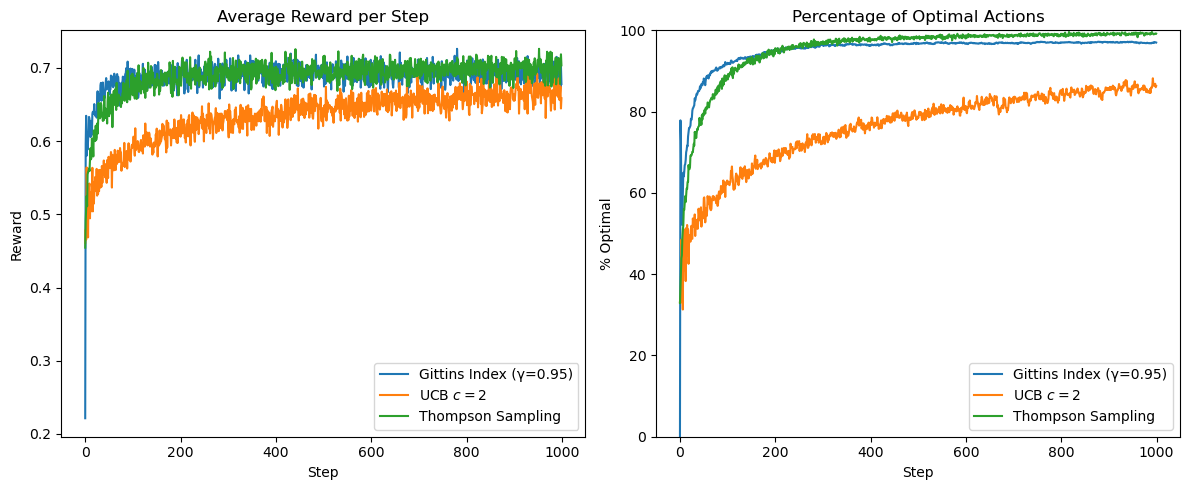

In [4]:
figure_GI(show=True)

## Bayesian-Adaptive Markov Decision Process (BAMDP)

## <span style="font-size: 0.8em;"> 1. The Core Problem: Acting When You Don't Know the Rules </span>
In a standard **Markov Decision Process (MDP)**, the agent knows the exact rules of the world—specifically, the transition probabilities $\mathcal{P}(s, a, s')$ that dictate where action $a$ in state $s$ will lead next. Because the rules are known, finding the best strategy is purely a planning problem.

In the real world, however, an agent rarely knows these transition probabilities in advance. At every step, it faces the **exploration–exploitation trade-off**:
* **Exploitation:** Using what it currently knows to gather immediate rewards.
* **Exploration:** Trying uncertain actions to learn how the world works so it can earn higher rewards in the future.

If the agent treats its current best guess of the rules as permanently fixed, it will fail to explore. Its optimal action today depends not only on *where it is*, but also on *what it has learned so far*.

---

## <span style="font-size: 0.8em;"> 2. The Big Idea: Turning Unknown Rules into Known "Belief States" </span>
The **Bayes-Adaptive MDP (BAMDP)** solves this dilemma with a clever mathematical transformation: **it converts uncertainty about the environment's rules into certainty inside an expanded ("augmented") state space.**

Instead of tracking only the physical state $s$, the agent tracks a **hyperstate** (or **augmented state**) $\langle s, h \rangle$:
1. **$s \in S$ (Physical State):** Where the agent currently is in the world.
2. **$h \in \mathcal{H}$ (Information State / History):** Everything the agent has experienced so far ($h_t = s_1 a_1 s_2 a_2 \dots a_{t-1} s_t$), which defines its current Bayesian belief distribution $P(\mathcal{P} \mid h)$ over the true rules of the environment. *(In many problems, this full history can be compressed into compact sufficient statistics, such as transition counts.)*

### <span style="font-size: 0.8em;"> Why This Works </span>
Even though the *true* physical dynamics $\mathcal{P}$ are hidden, **the dynamics of how the agent's beliefs update are completely known** (they follow Bayes' rule). By combining physical state and belief into a single hyperstate, the unknown MDP becomes a **completely known, standard MDP**—the BAMDP.

---

## <span style="font-size: 0.8em;"> 3. Mathematical Formulation </span>

A standard MDP is defined by the tuple $M = \langle S, A, \mathcal{P}, \mathcal{R}, \gamma \rangle$, where $S$ is the state space, $A$ is the action space, $\mathcal{P}$ is the transition kernel, $\mathcal{R}$ is the reward function, and $\gamma \in [0, 1)$ is the discount factor.

When $\mathcal{P}$ is unknown, the agent starts with a prior belief $P(\mathcal{P})$ and updates it via Bayes' rule after observing a transition $(s, a, s')$:

$$
P(\mathcal{P} \mid has') = \frac{\mathcal{P}(s, a, s')\, P(\mathcal{P} \mid h)}{\bar{\mathcal{P}}(s, a, s', h)}
$$

where $\bar{\mathcal{P}}(s, a, s', h)$ is the marginal probability of transitioning from $s$ to $s'$ under the agent's current belief:

$$
\bar{\mathcal{P}}(s, a, s', h) \equiv \int_{\mathcal{P}} \mathcal{P}(s, a, s')\, P(\mathcal{P} \mid h)\, d\mathcal{P}
$$

Using this belief update, we construct the **BAMDP** as the 5-tuple $M^+ = \langle S^+, A, \mathcal{P}^+, \mathcal{R}^+, \gamma \rangle$:

* **Augmented State Space (Hyperstates):**
  $$S^+ = S \times \mathcal{H}$$
* **Augmented Transition Dynamics:** Moving from hyperstate $\langle s, h \rangle$ to $\langle s', h' \rangle$ after taking action $a$ requires the new history to match $h' = has'$ and weights the transition by the current posterior belief:
  $$\mathcal{P}^+(\langle s, h \rangle, a, \langle s', h' \rangle) = \mathbb{I}[h' = has'] \int_{\mathcal{P}} \mathcal{P}(s, a, s')\, P(\mathcal{P} \mid h)\, d\mathcal{P}$$
* **Augmented Reward Function:** Immediate rewards depend only on the physical state and action:
  $$\mathcal{R}^+(\langle s, h \rangle, a) = \mathcal{R}(s, a)$$

### <span style="font-size: 0.8em;"> The BAMDP Bellman Equation </span>
Because all components of $M^+$ are known, we can write a standard Bellman equation over hyperstates for any adaptive policy $\tilde{\pi}$:

$$
V^{\tilde{\pi}}(s, h) = \sum_{a \in A} \tilde{\pi}(s, h, a) \left[ \mathcal{R}(s, a) + \gamma \sum_{s' \in S} \bar{\mathcal{P}}(s, a, s', h)\, V^{\tilde{\pi}}(s', has') \right]
$$

Similarly, the optimal action-value function $Q^*(\langle s_t, h_t \rangle, a)$ satisfies the Bellman optimality equation:

$$
Q^*(\langle s_t, h_t \rangle, a) = \mathcal{R}(s_t, a) + \gamma \sum_{s' \in S} \bar{\mathcal{P}}(s_t, a, s', h_t) \max_{a' \in A} Q^*(\langle s', h_t a s' \rangle, a')
$$

---

## <span style="font-size: 0.8em;"> 4. Why BAMDPs Are Special (And Why They Are Hard) </span>

### <span style="font-size: 0.8em;"> The Beauty: Bayes-Optimal Exploration Without Heuristics </span>
The greedy policy in the BAMDP—choosing $\arg\max_a Q^*(\langle s_t, h_t \rangle, a)$ at each step—is the **Bayes-optimal policy**. 
* It needs **no artificial exploration bonuses** (like $\epsilon$-greedy or UCB constants).
* By looking ahead at how future observations $has'$ change future beliefs, the agent automatically assigns higher value to actions that teach it useful information, while ignoring dead-end exploration that won't improve future rewards.

### <span style="font-size: 0.8em;"> The Catch: Computational Intractability </span>
Solving a BAMDP exactly is almost always impossible in practice for two major reasons:
1. **Infinite State Space ($S^+$):** Even if the physical MDP has only 5 states, there are infinitely many possible histories $h$ and belief states.
2. **Expensive Belief Integration:** Computing each transition probability $\bar{\mathcal{P}}(s, a, s', h)$ requires integrating over all possible models $\mathcal{P}$ using Bayes' rule at every single step of look-ahead planning.

*(This is precisely why sample-based online planners like **BAMCP** were invented—to approximate the BAMDP solution without exhaustively expanding every history or recomputing Bayes' rule inside the search tree.)*


## Simple Case Study: A Risk-averse RL Environment 

We test the BAMDP model using a simple risk-averse RL environment, where the agent is a mouse. The mouse should choose between a safe patch where it can get a small reward, or a dangerous patch where it can get a big reward. There is a probability $\theta$ (unknown to the agent) that a predator will show up. If the predator shows up, the agent travels to the predator-present state: the same physical state, but it represents a different internal state for the agent. From there, it needs to escape. If it succeeds, it gets back to the safe patch. If it fails, it dies with a very negative reward. Consequently, the agent needs to get more experience and to know $\theta$. This is precisely the essence of the BAMDP; the agent's policy/strategy adapts with uncertainty.  
<p align="center">
  <img src="BAMDP_ENV.png" alt="Risk-averse Enviornment" width="75%">
</p>


In [1]:
from BAMDP.Environment_Tree import *

These four plots tell the complete story of how a Bayes-Adaptive MDP (BAMDP) agent learns online, adapts its behavior to risk, and protects itself from catastrophic failure in the Mouse Foraging environment.
### 1. Top-Left: Distribution of Discounted Returns ($\theta = 0.40$)
This histogram shows the total discounted rewards earned across 500 simulated episodes when the true predator appearance probability is $\theta = 0.40$.

* **Bimodal Structure (Survival vs. Early Death):**
  * **Left Peak (Returns around $-15$ to $0$):** Represents episodes where the mouse encountered a predator (`P`) early and failed the escape roll ($1 - p_{\text{escape}} = 0.20$), ending the episode with the terminal penalty ($R_{\text{death}} = -25$). This is also why the average episode length is **15.0 steps** instead of the full 20-step horizon.
  * **Right Peak (Returns around $40$ to $50$):** Represents episodes where the mouse survived all 20 steps, harvesting high rewards at the dangerous patch (`D`) and safely managing its risk.
* **Overall Mean ($\mu = 28.51$):** The dashed red line shows the average return across both outcomes—balancing high foraging gains against occasional fatal encounters.

---

### 2. Top-Middle: Example Trajectory (Adaptive Behavior in Action)
This plot tracks a single 20-step episode through the physical states: **Safe (`S`)**, **Dangerous (`D`)**, **Predator (`P`)**, and **Death**. It illustrates the core strength of a BAMDP—**changing strategy as new evidence arrives**:

1. **Early Exploration ($t = 0$ to $9$):** Starting with an optimistic belief that the dangerous patch is relatively safe, the mouse moves to `D` and chooses to **stay and forage** ($a = 0$). It triggers a predator at $t = 2$ (escaping back to `S`), returns to `D` to forage repeatedly ($t = 6, 7, 8$), and triggers a second predator at $t = 9$.
2. **Behavioral Shift ($t = 10$ to $19$):** After surviving two predator encounters, the mouse realizes the patch is too risky to linger in. Instead of staying at `D`, it switches to a **cautious hit-and-run cycle (`S → D → S → D`)**—entering `D` to grab a reward and immediately retreating ($a = 1$) to avoid triggering `P` again.
3. **End-of-Horizon Exploitation ($t = 19 \to 20$):** On the very last step, the mouse stays at `D` because the episode ends at $t = 20$ before a predator attack can occur.

---

### 3. Top-Right: Posterior Belief Evolution Over $\theta$
This plot shows how the mouse's internal belief about $\theta$ updates via Bayes' rule during that exact same trajectory:

* **Initial Optimism ($t = 0$):** Under the $\text{Beta}(1, 9)$ prior, the mouse starts with an expected danger probability of $\mathbb{E}[\theta] = 0.10$ (solid black line), well below the true value of $\theta = 0.40$ (red dotted line).
* **Bayesian Jumps ($t = 2$ and $t = 9$):** Each time a predator appears at `P`, Bayes' rule updates the posterior upward—first jumping to $\mathbb{E}[\theta] \approx 0.18$ at $t = 2$, and then to $\approx 0.22$ at $t = 9$. Conversely, surviving at `D` without a predator ($t = 6$ to $8$) gently lowers $\mathbb{E}[\theta]$ back toward $0.15$.
* **Information Freeze ($t = 10$ to $19$):** Once the mouse switches to the safe `S → D → S → D` retreat cycle, it stops taking the risky stay action ($a = 0$) at `D`. Because no new predator trials occur, its belief curve flattens out—demonstrating the classic **exploration–exploitation stop**: once the agent learns enough to know staying is suboptimal, it stops exploring.

---

### 4. Bottom-Left: Performance Across All True $\theta$ Values
This curve evaluates the single Bayes-optimal policy across 50 different environments ranging from completely safe ($\theta \approx 0.01$) to nearly certain predator attacks ($\theta \approx 0.99$):

* **Low Danger ($\theta \to 0$):** Mean discounted return reaches nearly **70**, because the mouse discovers that `D` is safe and stays there continuously to collect maximum rewards.
* **Moderate Danger ($\theta \in [0.1, 0.4]$):** Performance declines smoothly as predator encounters become more frequent and force earlier retreats or occasional deaths.
* **High Danger Floor ($\theta > 0.5$):** Notice that the curve **does not crash to $-25$** even when $\theta \to 1.0$. Instead, it levels off around **20–25**. Because the BAMDP updates its belief after just one or two encounters and falls back to the safe `S → D → S → D` cycle, it prevents catastrophic losses even in extremely hostile environments.


Mean discounted return: 28.51 ± 22.44
Mean episode length:    15.0


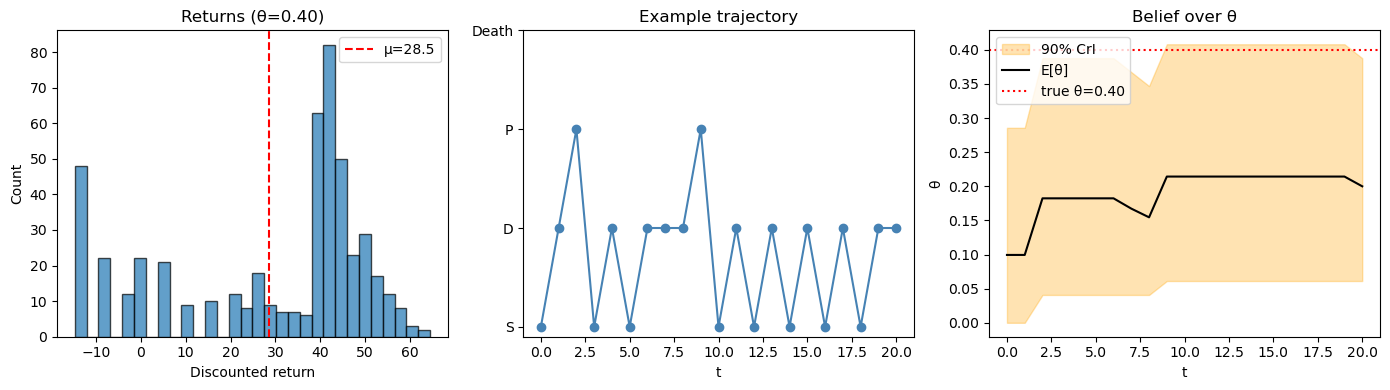

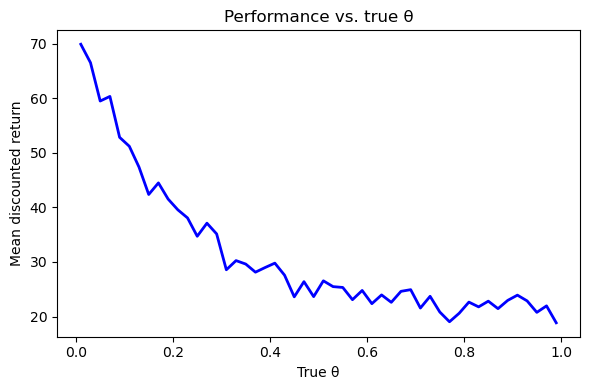

In [2]:
%matplotlib inline
from BAMDP.Environment import figure_bamdp

figure_bamdp(show=True)


## References

1. <a id="ref-1"></a>**Russo, D. J., Van Roy, B., Kazerouni, A., Osband, I., & Wen, Z. (2018).** *A Tutorial on Thompson Sampling.* Foundations and Trends in Machine Learning, 11(1), 1–96.  
   [[arXiv:1707.02038]](https://arxiv.org/abs/1707.02038) | [[PDF]](https://djrusso.github.io/docs/TS_Tutorial.pdf)

2. <a id="ref-2"></a>**Russo, D. (2019).** *Approximating Gittins Indices for Bayesian Bandits (A Note on Gittins Indices and Upper Confidence Bounds).*  
   [[arXiv:1904.04732]](https://arxiv.org)

3. <a id="ref-3"></a>**Guez, A., Silver, D., & Dayan, P. (2013).** *Scalable and Efficient Bayes-Adaptive Reinforcement Learning Based on Monte-Carlo Tree Search.* Journal of Artificial Intelligence Research (JAIR), 48, 841–883.  
   [[JAIR Article]](https://www.jair.org/index.php/jair/article/view/10853) | [[PDF]](https://www.gatsby.ucl.ac.uk/~aguez/files/guez_jair2013.pdf)

4. <a id="ref-4"></a>**Guez, A. (2015).** *Sample-Based Search Methods for Bayes-Adaptive Planning.* PhD Thesis, Gatsby Computational Neuroscience Unit, University College London (UCL).  
   [[UCL Discovery]](https://discovery.ucl.ac.uk/)
